# Clustering Mini Project: K-Means, DBSCAN and Hierarchical
**Group 6**

**Goal:** apply 3 clustering algorithms and compare them.

**Dataset:** Wine (from sklearn): 178 wines, 13 chemical features. The wines come from 3 grape types.
The algorithms never see the grape type; we only use it at the end to check the result.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target   # true grape type, used only to check the result
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 1. Data Preparation

In [ ]:
print("Missing values:", df.isna().sum().sum())

X = StandardScaler().fit_transform(df)

# PCA to 2 components, only to draw the clusters
X_2d = PCA(n_components=2).fit_transform(X)

Missing values: 0


No missing values. We scale the data because all 3 algorithms use distances.

## 2. K-Means

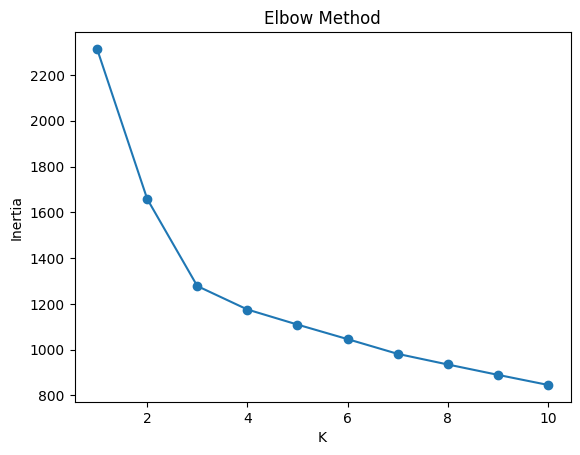

In [ ]:
inertia = []
for k in range(1, 11):
    inertia.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

The elbow is at **K = 3**.

In [ ]:
km_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)

## 3. DBSCAN

In [ ]:
for min_samples in [3, 5]:
    for eps in [1.8, 2.0, 2.2, 2.4, 2.6]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        print("min_samples", min_samples, "| eps", eps, "->", n_clusters, "clusters,", list(labels).count(-1), "noise")
    print()

min_samples 3 | eps 1.8 -> 8 clusters, 90 noise
min_samples 3 | eps 2.0 -> 5 clusters, 64 noise
min_samples 3 | eps 2.2 -> 3 clusters, 44 noise
min_samples 3 | eps 2.4 -> 2 clusters, 28 noise
min_samples 3 | eps 2.6 -> 1 clusters, 20 noise

min_samples 5 | eps 1.8 -> 7 clusters, 118 noise
min_samples 5 | eps 2.0 -> 5 clusters, 85 noise
min_samples 5 | eps 2.2 -> 2 clusters, 55 noise
min_samples 5 | eps 2.4 -> 2 clusters, 36 noise
min_samples 5 | eps 2.6 -> 1 clusters, 20 noise



* Small eps: many small clusters and a lot of noise.
* Large eps: everything becomes one cluster.
* Bigger min_samples: more points become noise.
* We choose **eps = 2.4, min_samples = 5**: 2 clear clusters without too many noise points (36).

In [ ]:
db_labels = DBSCAN(eps=2.4, min_samples=5).fit_predict(X)

## 4. Hierarchical Clustering

In [ ]:
for method in ["ward", "complete", "average"]:
    labels = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X)
    print(method, "-> silhouette:", round(silhouette_score(X, labels), 3))

ward -> silhouette: 0.277
complete -> silhouette: 0.204
average -> silhouette: 0.158


**Ward** gives the best silhouette, so we use it.

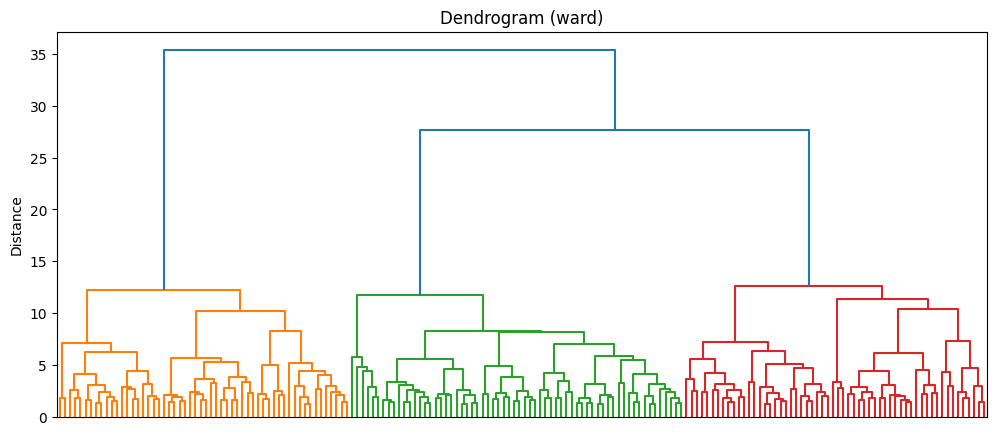

In [ ]:
plt.figure(figsize=(12, 5))
dendrogram(linkage(X, method="ward"), no_labels=True)
plt.title("Dendrogram (ward)")
plt.ylabel("Distance")
plt.show()

Cutting the tree where the vertical lines are longest gives **3 clusters**.

In [ ]:
hc_labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)

## 5. Visualization

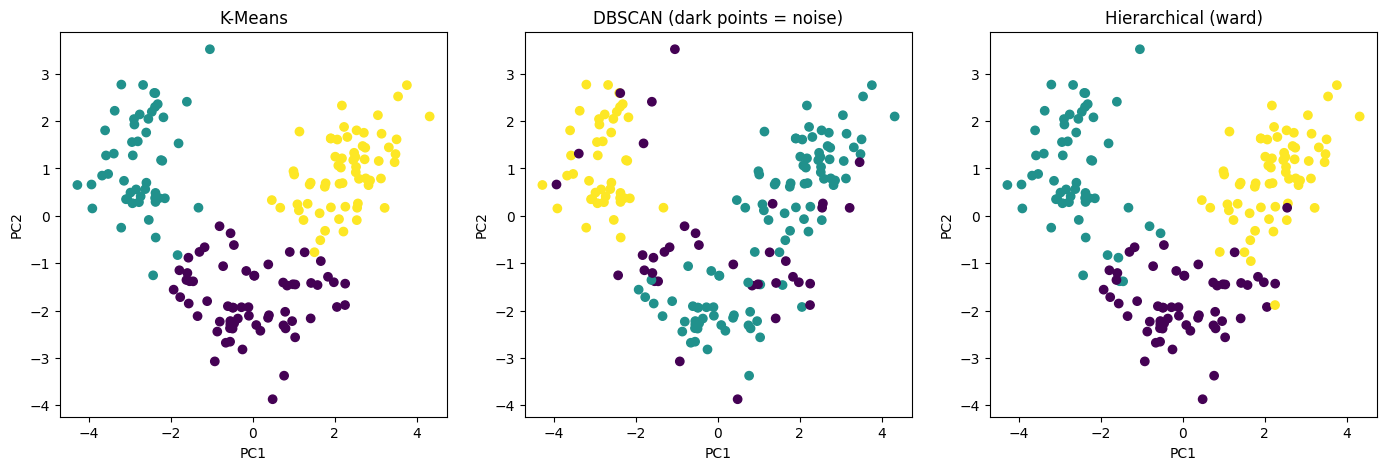

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

ax[0].scatter(X_2d[:, 0], X_2d[:, 1], c=km_labels, cmap="viridis")
ax[0].set_title("K-Means")

ax[1].scatter(X_2d[:, 0], X_2d[:, 1], c=db_labels, cmap="viridis")
ax[1].set_title("DBSCAN (dark points = noise)")

ax[2].scatter(X_2d[:, 0], X_2d[:, 1], c=hc_labels, cmap="viridis")
ax[2].set_title("Hierarchical (ward)")

for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.show()

The colours can differ between plots (cluster numbers are random); what matters is the groups.

## 6. Evaluation & Comparison

In [ ]:
not_noise = db_labels != -1   # silhouette for DBSCAN is measured without the noise points

results = pd.DataFrame({
    "Clusters": [3, len(set(db_labels)) - 1, 3],
    "Noise points": [0, list(db_labels).count(-1), 0],
    "Silhouette": [silhouette_score(X, km_labels),
                   silhouette_score(X[not_noise], db_labels[not_noise]),
                   silhouette_score(X, hc_labels)],
    "ARI (vs grape type)": [adjusted_rand_score(y, km_labels),
                            adjusted_rand_score(y, db_labels),
                            adjusted_rand_score(y, hc_labels)],
}, index=["K-Means", "DBSCAN", "Hierarchical"]).round(3)
results

,Clusters,Noise points,Silhouette,ARI (vs grape type)
K-Means,3,0,0.285,0.897
DBSCAN,2,36,0.327,0.421
Hierarchical,3,0,0.277,0.790


| | K-Means | DBSCAN | Hierarchical |
|---|---|---|---|
| **Cluster shape** | round, similar size | any shape | depends on linkage (ward: round) |
| **Number of clusters** | 3 (we choose K) | 2 (found by itself) | 3 (we cut the tree) |
| **Sensitivity to noise** | sensitive, every point gets a cluster | handles noise (36 noise points) | sensitive, every point gets a cluster |
| **ARI** | 0.90 | 0.42 | 0.79 |

DBSCAN's silhouette looks a bit higher only because its 36 noise points are left out. ARI is the fairer comparison here.

## 7. Critical Thinking

**Which algorithm performed best? Why?**
**K-Means** (ARI 0.90). The wine groups are round and similar in size, which is exactly what K-Means expects.
Hierarchical is close (0.79). DBSCAN is the weakest (0.42): it found only 2 clusters, because
the groups touch each other and have no clear empty space between them.

**When would you use each algorithm?**
* **K-Means:** when you know (or can guess) the number of clusters and the groups are round. Good for large data.
* **DBSCAN:** when clusters have strange shapes, you don't know how many there are, or the data has outliers.
* **Hierarchical:** on small data, when you want to see how the groups are related (dendrogram).

**Strengths and weaknesses**

| | Strengths | Weaknesses |
|---|---|---|
| **K-Means** | simple, fast | must choose K, only round clusters, affected by outliers |
| **DBSCAN** | finds K by itself, detects noise, any shape | hard to choose eps, weak when density is similar |
| **Hierarchical** | dendrogram shows the structure, no random start | slow on large data |

## 8. Final Summary (Key Insights)
* Scaling was needed because all 3 algorithms use distances.
* **K-Means** was the best (ARI 0.90), then **Hierarchical** (0.79), then **DBSCAN** (0.42).
* The wine data has 3 round groups that are close to each other, which suits K-Means and not DBSCAN.
* The best algorithm depends on the shape of the data.